# 01 · Data pipeline and exploratory analysis

**Question:** which tropical cyclones have actually threatened Jamaica since 1851, and what does a "typical" threat look like?

My first pass at this (a quick Power BI report) used every 6-hourly track point within 100 nm of the *centre* of the island. Two problems with that:

1. Jamaica is ~235 km long, so a centre-point radius under-counts storms skirting the east or west ends.
2. Counting track points is not counting storms. A slow storm contributes many rows and inflates the totals.

This version measures distance to the **coastline** (Natural Earth 1:10m), interpolates every track to **hourly** positions so a fast mover can't "jump" past the island between fixes, and summarises to **one row per storm**.

The tables are built by `scripts/build_dataset.py`; this notebook explores them.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from jhurricane import config, plotting as P

P.set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

storms = pd.read_csv(config.DATA_PROCESSED / "storms.csv", parse_dates=["closest_datetime"])
seasons = pd.read_csv(config.DATA_PROCESSED / "seasons.csv")
points = pd.read_csv(config.DATA_PROCESSED / "track_points.csv", parse_dates=["datetime"])
impacts = pd.read_csv(config.DATA_PROCESSED / "impacts.csv")
near = storms[storms["is_near"]].copy()

## Definitions

| Term | Meaning |
|---|---|
| **Near Jamaica** | Track passed within 100 nm (185 km) of the coast while at tropical-storm strength or above (≥ 34 kt) |
| **Intensity near Jamaica** | Highest sustained wind while within 100 nm. It can occur on the far side of the 100 nm ring, so it is a measure of threat rather than of winds felt on land |
| **Landfall** | Interpolated centre crossed the coastline, or HURDAT2 recorded a landfall fix within 5 nm of it |
| **Approach direction** | Where the storm was 24 h before its closest approach, as seen from the centre of the island |

In [2]:
print(f"Storms tracked within 600 nm of Jamaica: {len(storms):,}")
print(f"Storms near Jamaica (TS+ within 100 nm):  {len(near):,}")
print(f"  of which hurricanes: {near['is_hurricane_near'].sum()}, major (Cat 3+): {near['is_major_near'].sum()}")
print(f"Direct landfalls: {storms['jamaica_landfall'].sum()}")
print(f"Years covered: {seasons['year'].min()}-{seasons['year'].max()}")

Storms tracked within 600 nm of Jamaica: 898
Storms near Jamaica (TS+ within 100 nm):  104
  of which hurricanes: 55, major (Cat 3+): 18
Direct landfalls: 23
Years covered: 1851-2025


## Where the threats come from

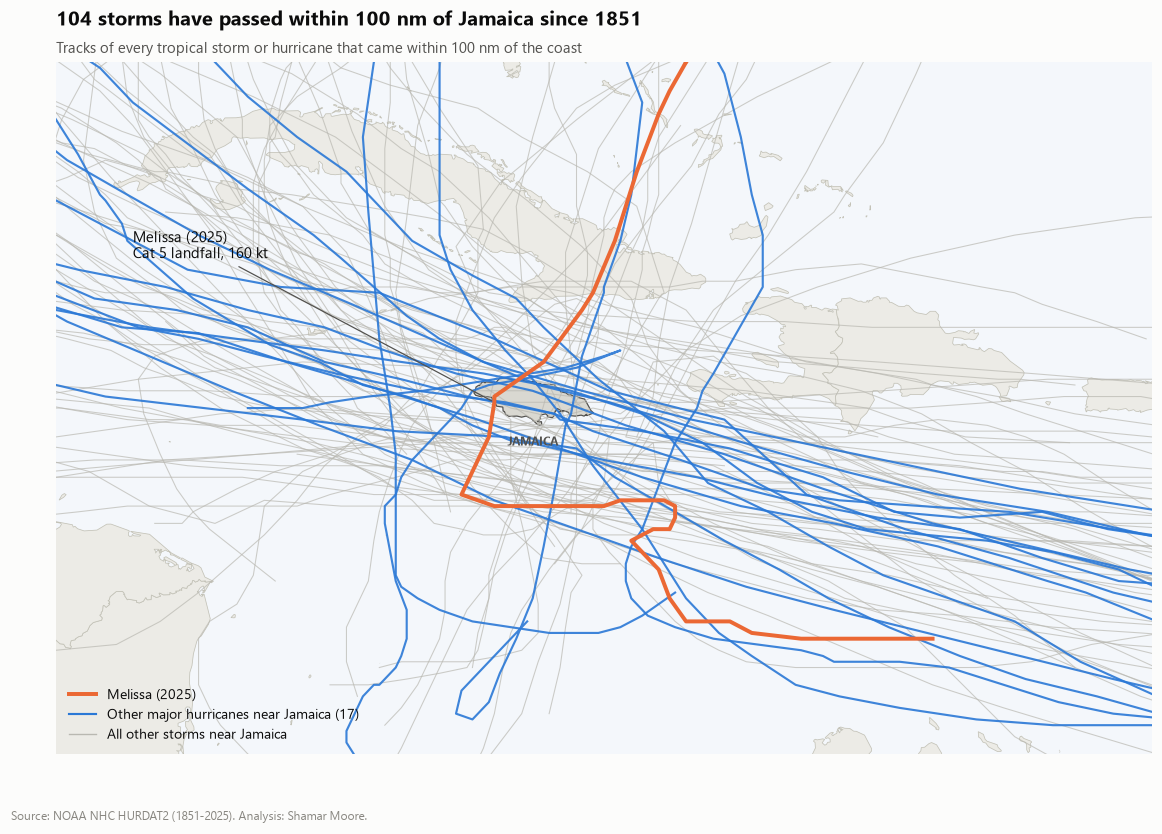

In [3]:
fig, ax = plt.subplots(figsize=(11, 7.4))
fig.subplots_adjust(left=0.02, right=0.98, top=0.9, bottom=0.05)
P.draw_basemap(ax)

ids_near = set(near["storm_id"])
majors = set(near.loc[near["is_major_near"], "storm_id"])
melissa = near.loc[near["storm_label"] == "Melissa (2025)", "storm_id"].iat[0]

for sid, g in points[points["storm_id"].isin(ids_near)].groupby("storm_id"):
    if sid in majors or sid == melissa:
        continue
    ax.plot(g["lon"], g["lat"], color=P.GRAY, lw=0.7, alpha=0.7, zorder=2)
for sid, g in points[points["storm_id"].isin(majors - {melissa})].groupby("storm_id"):
    ax.plot(g["lon"], g["lat"], color=P.BLUE, lw=1.4, alpha=0.9, zorder=3)
g = points[points["storm_id"] == melissa]
ax.plot(g["lon"], g["lat"], color=P.ORANGE, lw=2.6, zorder=4)

ax.annotate("Melissa (2025)\nCat 5 landfall, 160 kt", xy=(-78.0, 18.1), xytext=(-84.6, 20.6),
            fontsize=9.5, color=P.INK, arrowprops=dict(arrowstyle="-", color=P.INK_2, lw=0.8))
ax.text(-77.3, 17.35, "JAMAICA", ha="center", fontsize=8, color=P.INK_2, weight="bold")

from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], color=P.ORANGE, lw=2.6, label="Melissa (2025)"),
                   Line2D([], [], color=P.BLUE, lw=1.4, label="Other major hurricanes near Jamaica (17)"),
                   Line2D([], [], color=P.GRAY, lw=0.9, label="All other storms near Jamaica")],
          loc="lower left", fontsize=9)
ax.set_title("104 storms have passed within 100 nm of Jamaica since 1851")
P.subtitle(ax, "Tracks of every tropical storm or hurricane that came within 100 nm of the coast")
P.source_note(fig)
fig.savefig(config.FIGURES / "01_tracks_map.png")
plt.show()

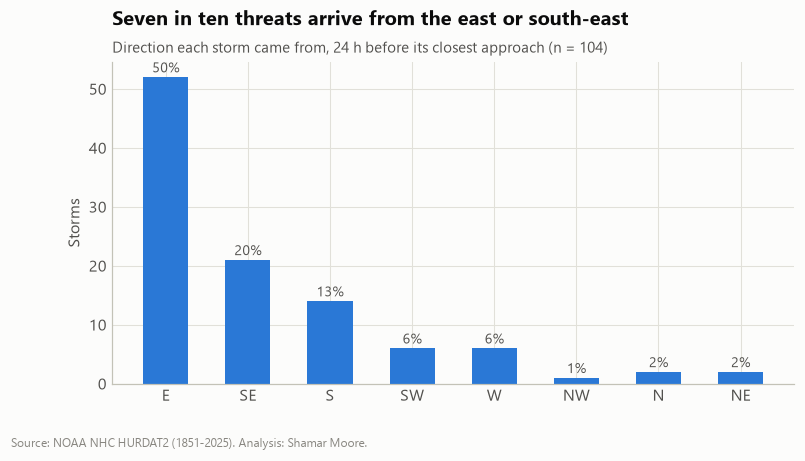

East + south-east share: 70%


In [4]:
order = ["E", "SE", "S", "SW", "W", "NW", "N", "NE"]
approach = near["approach_from"].value_counts().reindex(order, fill_value=0)
share = approach / approach.sum()

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(order, approach.values, color=P.BLUE, width=0.55)
for b, s in zip(bars, share.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8, f"{s:.0%}", ha="center", fontsize=9, color=P.INK_2)
ax.set_ylabel("Storms")
ax.set_title("Seven in ten threats arrive from the east or south-east")
P.subtitle(ax, "Direction each storm came from, 24 h before its closest approach (n = 104)")
P.source_note(fig)
fig.savefig(config.FIGURES / "01_approach_direction.png")
plt.show()
print(f"East + south-east share: {share[['E', 'SE']].sum():.0%}")

Most storms ride the trade-wind easterlies through the Caribbean, so the east and south-east dominate. The less common ones are worth noting, though. Late-season storms that form in the south-west Caribbean and move **north-east** (Sandy 2012, Melissa 2025, the November 1912 storm) approach from the S or SW. They tend to reach the south coast, where Kingston and most of the population sit, with little lead time.

## When in the season

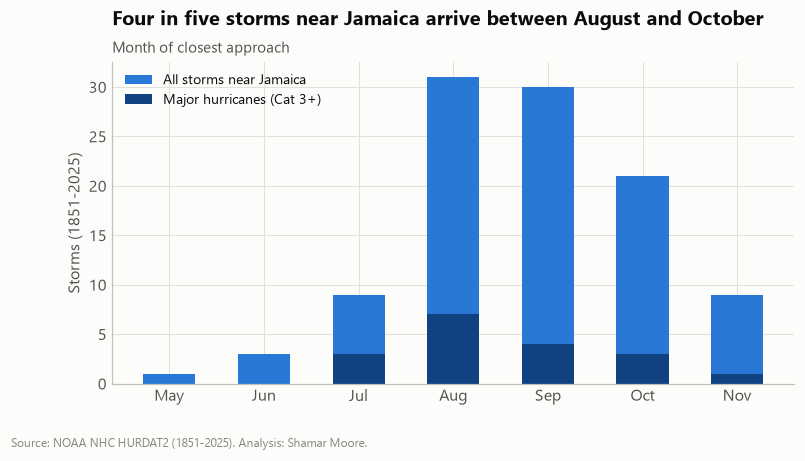

May    0.010
Jun    0.029
Jul    0.087
Aug    0.298
Sep    0.288
Oct    0.202
Nov    0.087
Name: count, dtype: float64


In [5]:
months = near["closest_month"].value_counts().reindex(range(5, 12), fill_value=0)
labels = ["May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov"]
majors_m = near[near["is_major_near"]]["closest_month"].value_counts().reindex(range(5, 12), fill_value=0)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(labels, months.values, color=P.BLUE, width=0.55, label="All storms near Jamaica")
ax.bar(labels, majors_m.values, color=P.INTENSITY["Cat 4"], width=0.55, label="Major hurricanes (Cat 3+)")
ax.set_ylabel("Storms (1851-2025)")
ax.legend(loc="upper left", fontsize=9)
ax.set_title("Four in five storms near Jamaica arrive between August and October")
P.subtitle(ax, "Month of closest approach")
P.source_note(fig)
fig.savefig(config.FIGURES / "01_seasonality.png")
plt.show()
print((months / months.sum()).round(3).set_axis(labels))

## How strong

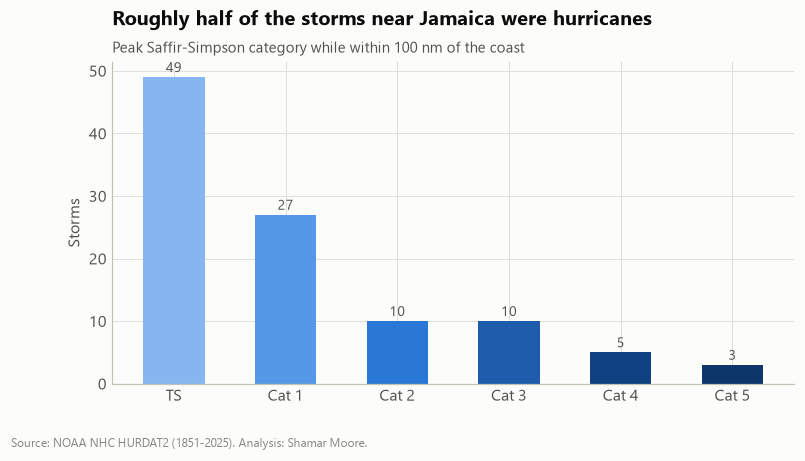

In [6]:
cats = ["TS", "Cat 1", "Cat 2", "Cat 3", "Cat 4", "Cat 5"]
dist = near["category_near_jamaica"].value_counts().reindex(cats, fill_value=0)

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(cats, dist.values, color=[P.INTENSITY[c] for c in cats], width=0.55)
for b, v in zip(bars, dist.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8, str(v), ha="center", fontsize=9, color=P.INK_2)
ax.set_ylabel("Storms")
ax.set_title("Roughly half of the storms near Jamaica were hurricanes")
P.subtitle(ax, "Peak Saffir-Simpson category while within 100 nm of the coast")
P.source_note(fig)
fig.savefig(config.FIGURES / "01_intensity_distribution.png")
plt.show()

In [7]:
cols = ["storm_label", "closest_datetime", "max_wind_within_100nm_kt", "min_pressure_within_100nm_mb",
        "closest_distance_nm", "approach_from", "jamaica_landfall", "rapid_intensification"]
near.sort_values("max_wind_within_100nm_kt", ascending=False)[cols].head(12).reset_index(drop=True)

,storm_label,closest_datetime,max_wind_within_100nm_kt,min_pressure_within_100nm_mb,closest_distance_nm,approach_from,jamaica_landfall,rapid_intensification
0,Melissa (2025),2025-10-28 18:00:00,165.0,892.0,0.0,SW,True,True
1,Ivan (2004),2004-09-11 04:00:00,145.0,910.0,19.1,SE,False,False
2,Emily (2005),2005-07-16 20:00:00,140.0,929.0,85.6,SE,False,True
3,Allen (1980),1980-08-06 07:00:00,132.0,948.0,18.6,E,False,True
4,Dean (2007),2007-08-19 22:00:00,130.0,925.0,20.3,E,False,True
5,Beryl (2024),2024-07-03 22:00:00,125.0,951.0,13.9,E,False,True
6,Dennis (2005),2005-07-07 18:00:00,120.0,951.0,25.1,SE,False,True
7,Gilbert (1988),1988-09-12 19:00:00,117.0,949.0,0.0,E,True,True
8,Charlie (1951),1951-08-18 04:00:00,110.0,971.0,0.0,E,True,True
9,Unnamed (1903),1903-08-11 09:00:00,105.0,959.0,0.0,E,True,True


### Takeaways

* **104 storms in 175 years**, about one every 1.7 seasons on average. 55 were hurricanes and 18 were major hurricanes.
* Threats come overwhelmingly from the **east / south-east**. The rarer south-westerly approach includes two of the most damaging storms of the past 15 years.
* **Aug-Oct** accounts for 79% of activity. October alone still carries one storm in five, and two of the three most recent landfalls (Sandy 2012, Melissa 2025) were October storms. October isn't a quiet tail here.
* The strongest storms ever recorded near Jamaica, **Melissa (165 kt)** and **Ivan (145 kt)**, both occurred in the last 25 years.